In [1]:
import os
import nibabel as nib
import glob


In [2]:
BASE_DIR = os.path.dirname(os.path.abspath(os.getcwd()))

RAW_DATA_DIR = os.path.join(BASE_DIR, 'train_data_racellete_4dflow')
print(RAW_DATA_DIR)
IMAGES_SOURCE = os.path.join(RAW_DATA_DIR, 'ao_imgs')
LABELS_SOURCE = os.path.join(RAW_DATA_DIR, 'ao_segs')

print(f"Source images: {IMAGES_SOURCE}")
print(f"Source labels: {LABELS_SOURCE}")


d:\projects\4D-flow-MRI-aortic-segmentation-\train_data_racellete_4dflow
Source images: d:\projects\4D-flow-MRI-aortic-segmentation-\train_data_racellete_4dflow\ao_imgs
Source labels: d:\projects\4D-flow-MRI-aortic-segmentation-\train_data_racellete_4dflow\ao_segs


In [4]:

from collections import Counter


img_orient_counter = Counter()
lbl_orient_counter = Counter()

for lbl_name in os.listdir(LABELS_SOURCE):
    if not lbl_name.endswith(".nii.gz"):
        continue

    img_name = lbl_name.replace(".nii.gz", "_0000.nii.gz")
    img_path = os.path.join(IMAGES_SOURCE, img_name)
    lbl_path = os.path.join(LABELS_SOURCE, lbl_name)

    if not os.path.exists(img_path):
        continue

    img = nib.load(img_path)
    print(img.header.get_zooms())
    lbl = nib.load(lbl_path)

    img_orient = nib.aff2axcodes(img.affine)
    lbl_orient = nib.aff2axcodes(lbl.affine)

    img_orient_counter[img_orient] += 1
    lbl_orient_counter[lbl_orient] += 1


print("=== IMAGE ORIENTATIONS ===")
print(f"RAS count     : {img_orient_counter[('R','A','S')]}")
print(f"Non‑RAS count : {sum(img_orient_counter.values()) - img_orient_counter[('R','A','S')]}")
print("Breakdown:", dict(img_orient_counter))

print("\n=== LABEL ORIENTATIONS ===")
print(f"RAS count     : {lbl_orient_counter[('R','A','S')]}")
print(f"Non‑RAS count : {sum(lbl_orient_counter.values()) - lbl_orient_counter[('R','A','S')]}")
print("Breakdown:", dict(lbl_orient_counter))


(2.022405, 2.0043998, 2.3330564)
(2.022405, 2.0043998, 2.3330564)
(2.022405, 2.0043998, 2.3330564)
(2.022405, 2.0043998, 2.3330564)
(2.022405, 2.0043998, 2.3330564)
(2.022405, 2.0043998, 2.3330564)
(2.022405, 2.0043998, 2.3330564)
(2.022405, 2.0043998, 2.3330564)
(2.022405, 2.0043998, 2.3330564)
(2.022405, 2.0043998, 2.3330564)
(2.022405, 2.0043998, 2.3330564)
(2.022405, 2.0043998, 2.3330564)
(2.022405, 2.0043998, 2.3330564)
(2.022405, 2.0043998, 2.3330564)
(2.022405, 2.0043998, 2.3330564)
(2.022405, 2.0043998, 2.3330564)
(2.022405, 2.0043998, 2.3330564)
(2.022405, 2.0043998, 2.3330564)
(2.022405, 2.0043998, 2.3330564)
(2.022405, 2.0043998, 2.3330564)
(2.022405, 2.0043998, 2.3330564)
(2.022405, 2.0043998, 2.3330564)
(2.022405, 2.0043998, 2.3330564)
(2.022405, 2.0043998, 2.3330564)
(2.022405, 2.0043998, 2.3330564)
(2.046154, 2.0446365, 2.0269024)
(2.046154, 2.0446365, 2.0269024)
(2.046154, 2.0446365, 2.0269024)
(2.046154, 2.0446365, 2.0269024)
(2.046154, 2.0446365, 2.0269024)
(2.046154,

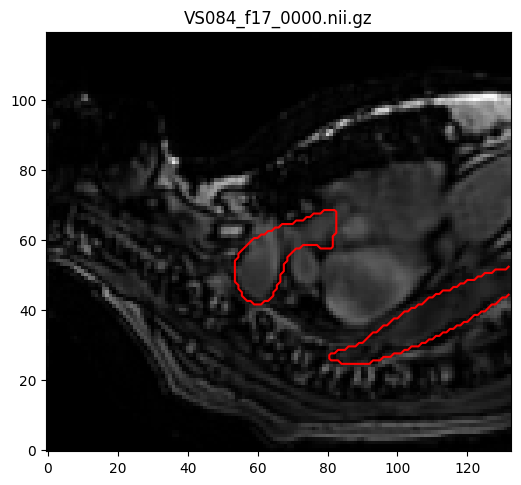

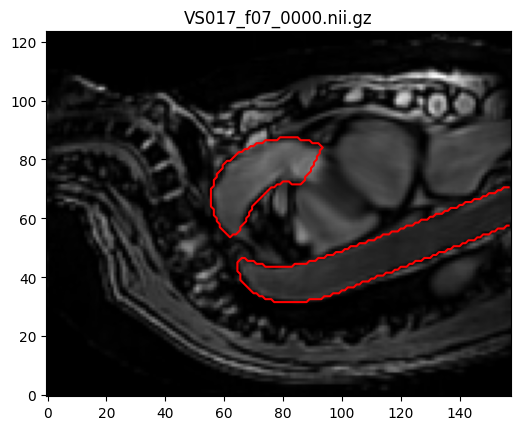

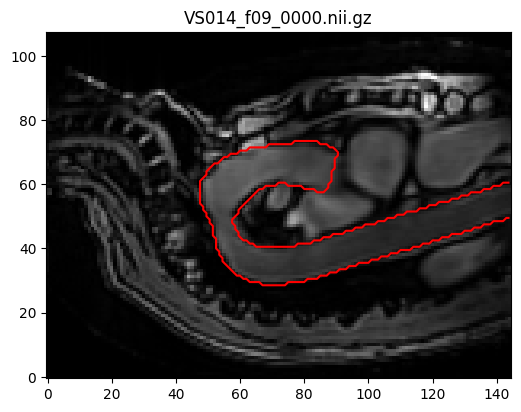

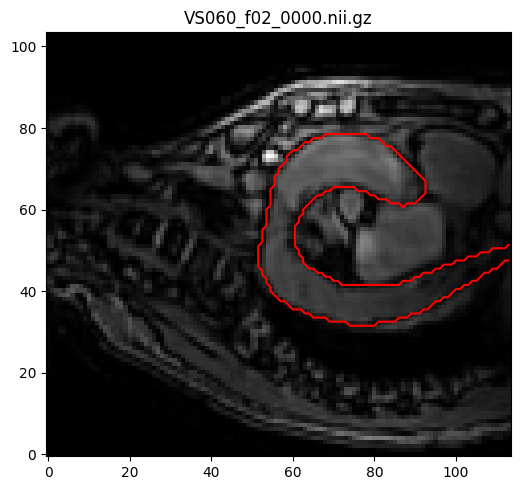

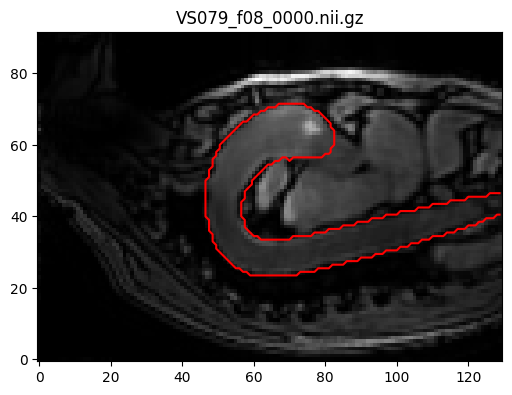

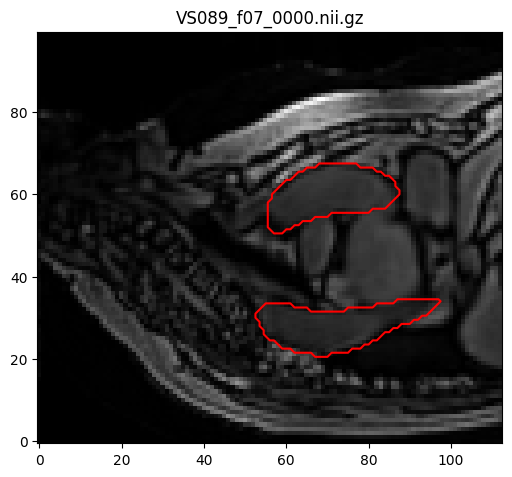

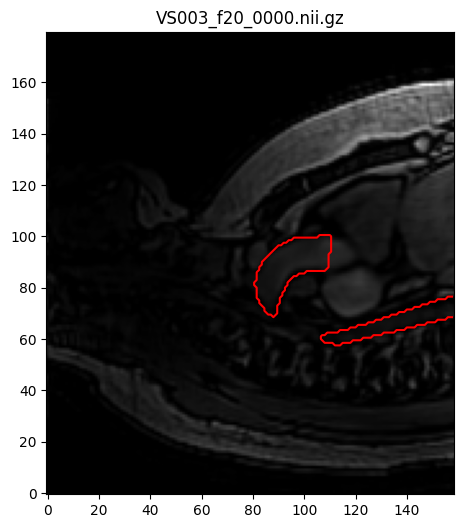

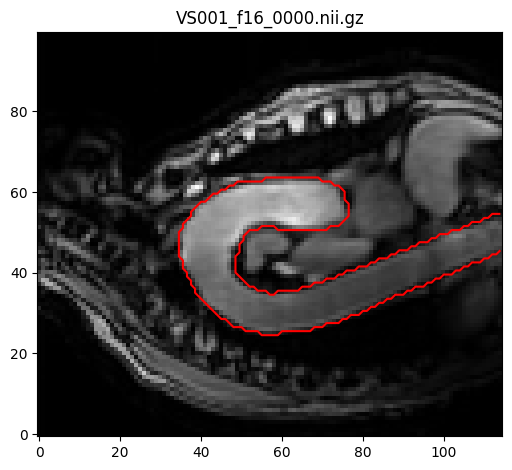

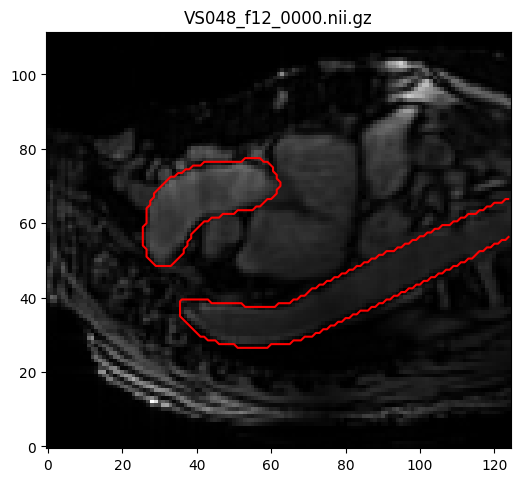

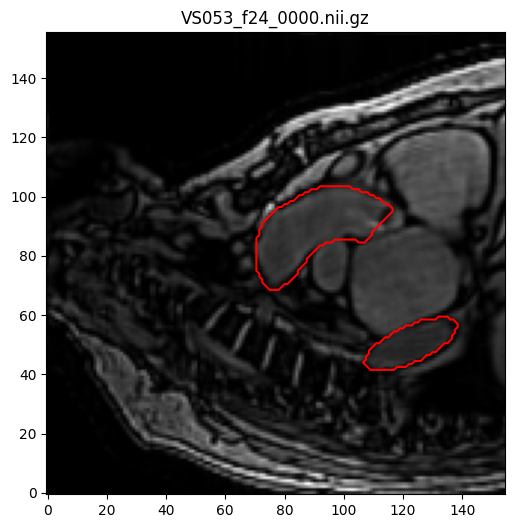

In [5]:
import random
import nibabel as nib
import matplotlib.pyplot as plt
from pathlib import Path



img_files = list(Path(IMAGES_SOURCE).glob("*.nii.gz"))

for f in random.sample(img_files, 10):

    seg_f = Path(LABELS_SOURCE) / f.name.replace("_0000", "")

    img = nib.load(str(f)).get_fdata()
    seg = nib.load(str(seg_f)).get_fdata()

    z = img.shape[2] // 2

    plt.figure(figsize=(6,6))
    plt.imshow(img[:,:,z].T, cmap="gray", origin="lower")
    plt.contour(seg[:,:,z].T, levels=[0.5], colors="r")
    plt.title(f.name)
    plt.show()